In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Statistical testing
from scipy import stats
from scipy.stats import ttest_ind

# Machine learning
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             roc_curve, auc, f1_score, accuracy_score, balanced_accuracy_score)

In [2]:
pm=pd.read_csv('/content/drive/MyDrive/Industrial Pump maintenance/Large_Industrial_Pump_Maintenance_Dataset.csv')

In [3]:
pm

,Pump_ID,Temperature,Vibration,Pressure,Flow_Rate,RPM,Operational_Hours,Maintenance_Flag
0,2,127.508350,2.369397,136.021029,6.501492,1444.191922,3966.793672,1
1,4,88.975185,4.541126,147.516973,7.001516,1004.802496,3673.288933,0
2,3,61.832325,2.542112,220.858577,8.824368,2597.662712,5489.061016,1
3,3,106.250344,2.834452,145.817091,16.283512,2280.926281,3134.783015,0
4,2,84.815865,3.119709,235.476221,8.385183,2594.131667,761.533173,1
...,...,...,...,...,...,...,...,...
19995,5,133.824387,2.193536,162.072728,6.272785,1939.452036,4327.831926,1
19996,1,100.976892,4.906084,109.160420,10.000945,2267.788691,7474.000467,1
19997,3,109.563715,0.769374,180.743971,18.706712,2758.781582,8935.787395,1
19998,3,116.730910,3.279518,289.369874,14.570612,1683.361885,4576.992294,0


In [4]:
pm.isnull().sum()

,0
Pump_ID,0
Temperature,0
Vibration,0
Pressure,0
Flow_Rate,0
RPM,0
Operational_Hours,0
Maintenance_Flag,0


In [5]:
pm.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Pump_ID            20000 non-null  int64  
 1   Temperature        20000 non-null  float64
 2   Vibration          20000 non-null  float64
 3   Pressure           20000 non-null  float64
 4   Flow_Rate          20000 non-null  float64
 5   RPM                20000 non-null  float64
 6   Operational_Hours  20000 non-null  float64
 7   Maintenance_Flag   20000 non-null  int64  
dtypes: float64(6), int64(2)
memory usage: 1.2 MB


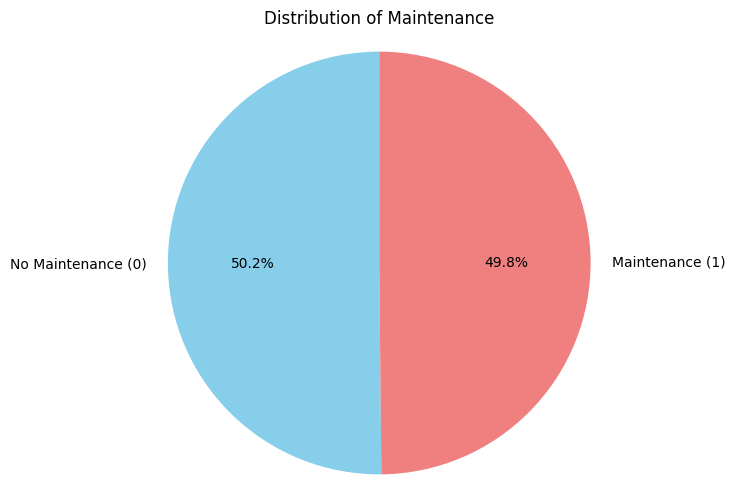

In [6]:
maintenance_counts = pm['Maintenance_Flag'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(maintenance_counts, labels=['No Maintenance (0)', 'Maintenance (1)'], autopct='%1.1f%%', startangle=90, colors=['skyblue', 'lightcoral'])
plt.title('Distribution of Maintenance')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

In [7]:
pm.groupby('Pump_ID')['Maintenance_Flag'].mean()

,Maintenance_Flag
Pump_ID,
1,0.502429
2,0.498668
3,0.499110
4,0.505699
5,0.486101


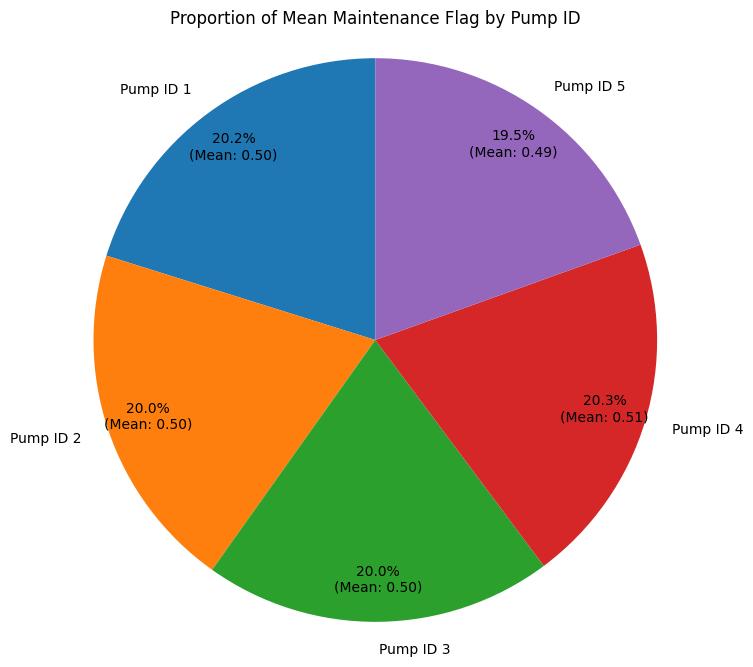

In [8]:
mean_maintenance_by_pump = pm.groupby('Pump_ID')['Maintenance_Flag'].mean()

plt.figure(figsize=(8, 8))

# A custom function for autopct to display both percentage and the actual mean value for each slice
def make_autopct(all_values):
    total_sum = sum(all_values)
    def my_autopct(pct):
        absolute_value_for_slice = (pct / 100.0) * total_sum
        return f'{pct:.1f}%\n(Mean: {absolute_value_for_slice:.2f})'
    return my_autopct

plt.pie(
    mean_maintenance_by_pump.values, # Pass the values directly for the pie chart sizes
    labels=[f'Pump ID {i}' for i in mean_maintenance_by_pump.index],
    autopct=make_autopct(mean_maintenance_by_pump.values),
    startangle=90,
    pctdistance=0.85
)

plt.title('Proportion of Mean Maintenance Flag by Pump ID')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

In [9]:
pm.corr()

,Pump_ID,Temperature,Vibration,Pressure,Flow_Rate,RPM,Operational_Hours,Maintenance_Flag
Pump_ID,1.000000,-0.001789,-0.007424,-0.006483,0.007246,-0.003809,-0.002971,-0.007189
Temperature,-0.001789,1.000000,-0.003828,0.010348,-0.007030,-0.002716,-0.005662,-0.013055
Vibration,-0.007424,-0.003828,1.000000,-0.000670,-0.010816,0.014048,0.006401,0.007575
Pressure,-0.006483,0.010348,-0.000670,1.000000,0.011846,0.013011,0.004281,-0.005164
Flow_Rate,0.007246,-0.007030,-0.010816,0.011846,1.000000,0.001757,-0.004263,0.008674
RPM,-0.003809,-0.002716,0.014048,0.013011,0.001757,1.000000,0.008139,-0.008564
Operational_Hours,-0.002971,-0.005662,0.006401,0.004281,-0.004263,0.008139,1.000000,-0.003098
Maintenance_Flag,-0.007189,-0.013055,0.007575,-0.005164,0.008674,-0.008564,-0.003098,1.000000


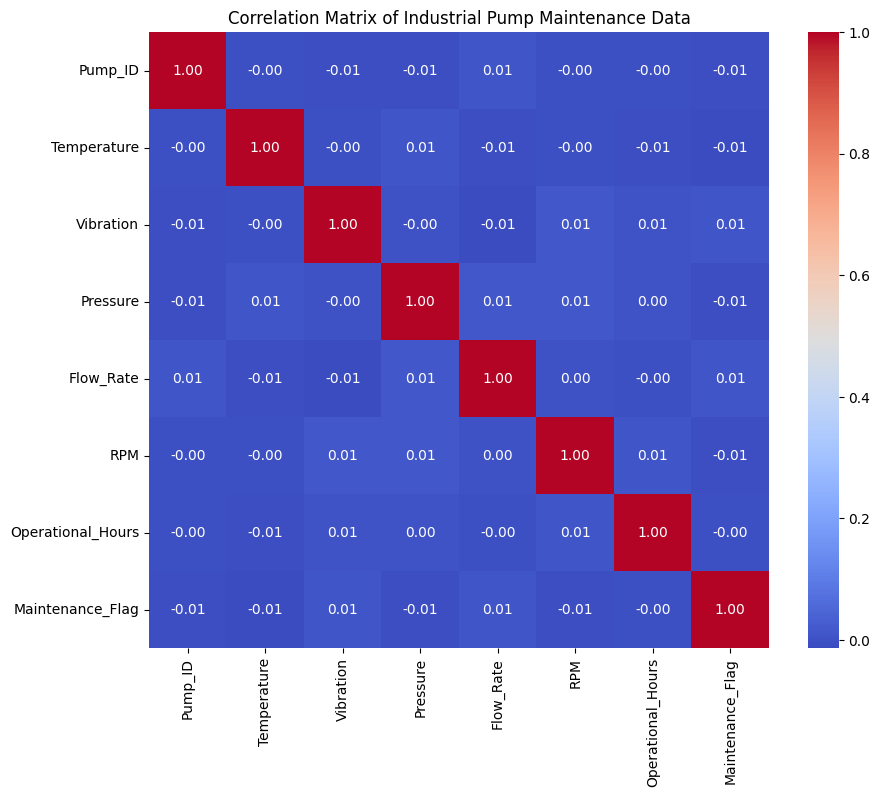

In [10]:
plt.figure(figsize=(10, 8))
sns.heatmap(pm.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Industrial Pump Maintenance Data')
plt.show()

In [11]:
pm_clone = pm.copy()
display(pm_clone.head())

,Pump_ID,Temperature,Vibration,Pressure,Flow_Rate,RPM,Operational_Hours,Maintenance_Flag
0,2,127.508350,2.369397,136.021029,6.501492,1444.191922,3966.793672,1
1,4,88.975185,4.541126,147.516973,7.001516,1004.802496,3673.288933,0
2,3,61.832325,2.542112,220.858577,8.824368,2597.662712,5489.061016,1
3,3,106.250344,2.834452,145.817091,16.283512,2280.926281,3134.783015,0
4,2,84.815865,3.119709,235.476221,8.385183,2594.131667,761.533173,1


In [12]:
pm_clone.drop(columns=['Pump_ID'], inplace=True)
pm_clone.head()

,Temperature,Vibration,Pressure,Flow_Rate,RPM,Operational_Hours,Maintenance_Flag
0,127.508350,2.369397,136.021029,6.501492,1444.191922,3966.793672,1
1,88.975185,4.541126,147.516973,7.001516,1004.802496,3673.288933,0
2,61.832325,2.542112,220.858577,8.824368,2597.662712,5489.061016,1
3,106.250344,2.834452,145.817091,16.283512,2280.926281,3134.783015,0
4,84.815865,3.119709,235.476221,8.385183,2594.131667,761.533173,1


In [13]:
pm_clone.groupby('Maintenance_Flag')[['Temperature','Vibration']].mean()

,Temperature,Vibration
Maintenance_Flag,,
0,100.746785,2.517161
1,99.993484,2.538619


In [14]:
pm_clone.groupby('Maintenance_Flag')[['RPM','Operational_Hours']].mean()

,RPM,Operational_Hours
Maintenance_Flag,,
0,2010.538768,5039.337827
1,2000.664014,5021.567381


In [15]:
maint_counts = pm_clone['Maintenance_Flag'].value_counts()
maint_pct = pm_clone['Maintenance_Flag'].value_counts(normalize=True) * 100
print(f"\n{'Maintenance Distribution':^80}")
print(f"No Maintenance (0): {maint_counts[0]:,} ({maint_pct[0]:.2f}%)")
print(f"Maintenance Required (1): {maint_counts[1]:,} ({maint_pct[1]:.2f}%)")


                            Maintenance Distribution                            
No Maintenance (0): 10,032 (50.16%)
Maintenance Required (1): 9,968 (49.84%)


In [16]:
# 2. STATISTICAL SIGNIFICANCE TESTING
# ============================================================================

print("\n" + "="*80)
print("STEP 2: STATISTICAL SIGNIFICANCE TESTING")
print("="*80)
print("Testing if feature distributions differ between maintenance groups\n")

features = ['Temperature', 'Vibration', 'Pressure', 'Flow_Rate', 'RPM', 'Operational_Hours']
statistical_results = []

for feature in features:
    maint_group = pm_clone[pm_clone['Maintenance_Flag'] == 1][feature]
    no_maint_group = pm_clone[pm_clone['Maintenance_Flag'] == 0][feature]

    # T-test
    t_stat, p_value = ttest_ind(maint_group, no_maint_group)

    # Effect size (Cohen's d)
    cohens_d = (maint_group.mean() - no_maint_group.mean()) / \
               np.sqrt((maint_group.std()**2 + no_maint_group.std()**2) / 2)

    mean_diff = maint_group.mean() - no_maint_group.mean()

    statistical_results.append({
        'Feature': feature,
        'Maint_Mean': maint_group.mean(),
        'NoMaint_Mean': no_maint_group.mean(),
        'Mean_Diff': mean_diff,
        'T_Stat': t_stat,
        'P_Value': p_value,
        'Cohens_d': cohens_d
    })

    sig = "***" if p_value < 0.001 else "**" if p_value < 0.01 else "*" if p_value < 0.05 else "ns"
    print(f"{feature}:")
    print(f"  Maintenance Mean: {maint_group.mean():.4f} | No Maint Mean: {no_maint_group.mean():.4f}")
    print(f"  Difference: {mean_diff:.4f} | T-stat: {t_stat:.4f} | p-value: {p_value:.4e} {sig}")
    print(f"  Cohen's d (effect size): {cohens_d:.4f} (negligible)\n")

stats_df = pd.DataFrame(statistical_results)
print(stats_df.to_string(index=False))


STEP 2: STATISTICAL SIGNIFICANCE TESTING
Testing if feature distributions differ between maintenance groups

Temperature:
  Maintenance Mean: 99.9935 | No Maint Mean: 100.7468
  Difference: -0.7533 | T-stat: -1.8463 | p-value: 6.4858e-02 ns
  Cohen's d (effect size): -0.0261 (negligible)

Vibration:
  Maintenance Mean: 2.5386 | No Maint Mean: 2.5172
  Difference: 0.0215 | T-stat: 1.0712 | p-value: 2.8409e-01 ns
  Cohen's d (effect size): 0.0151 (negligible)

Pressure:
  Maintenance Mean: 200.0821 | No Maint Mean: 200.6792
  Difference: -0.5971 | T-stat: -0.7302 | p-value: 4.6526e-01 ns
  Cohen's d (effect size): -0.0103 (negligible)

Flow_Rate:
  Maintenance Mean: 10.2972 | No Maint Mean: 10.1993
  Difference: 0.0979 | T-stat: 1.2266 | p-value: 2.1998e-01 ns
  Cohen's d (effect size): 0.0173 (negligible)

RPM:
  Maintenance Mean: 2000.6640 | No Maint Mean: 2010.5388
  Difference: -9.8748 | T-stat: -1.2112 | p-value: 2.2584e-01 ns
  Cohen's d (effect size): -0.0171 (negligible)

Operat


Correlation with Maintenance Flag:
Maintenance_Flag     1.000000
Flow_Rate            0.008674
Vibration            0.007575
Operational_Hours   -0.003098
Pressure            -0.005164
RPM                 -0.008564
Temperature         -0.013055
Name: Maintenance_Flag, dtype: float64

Interpretation: All correlations < 0.015 indicate NO linear relationship


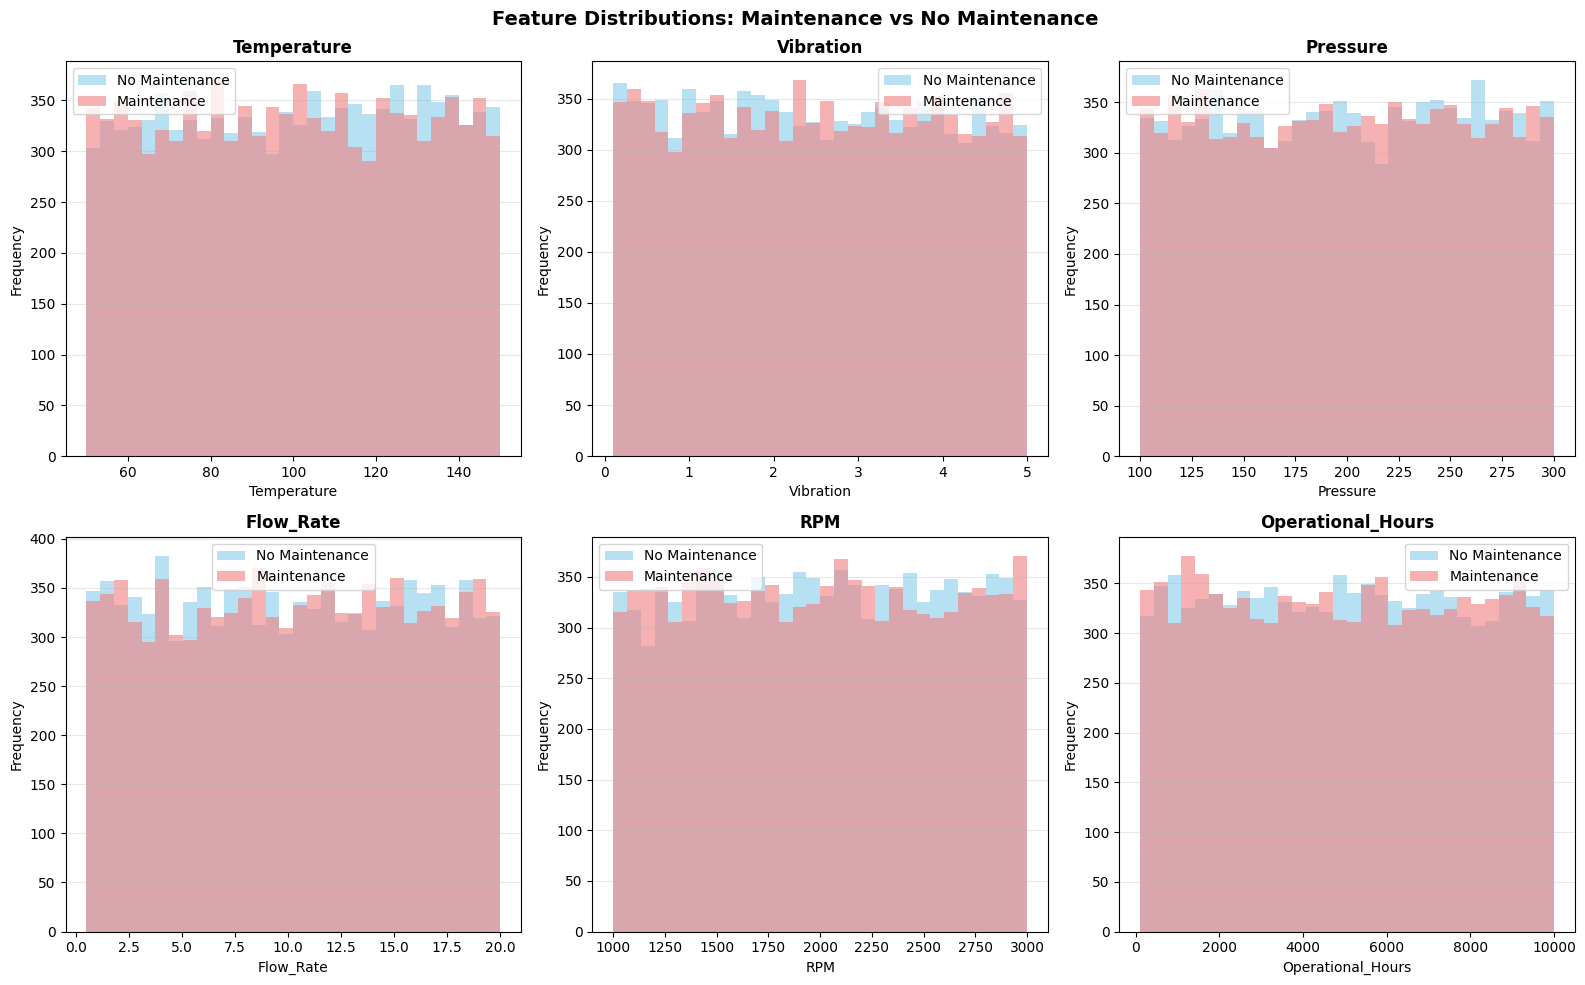

In [17]:
# 3. CORRELATION ANALYSIS
corr_matrix = pm_clone.corr()
maint_corr = corr_matrix['Maintenance_Flag'].sort_values(ascending=False)
print("\nCorrelation with Maintenance Flag:")
print(maint_corr)
print("\nInterpretation: All correlations < 0.015 indicate NO linear relationship")

# Visualization
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Feature Distributions: Maintenance vs No Maintenance', fontsize=14, fontweight='bold')
axes = axes.flatten()

for idx, feature in enumerate(features):
    ax = axes[idx]
    maint = pm_clone[pm_clone['Maintenance_Flag'] == 1][feature]
    no_maint = pm_clone[pm_clone['Maintenance_Flag'] == 0][feature]

    ax.hist(no_maint, bins=30, alpha=0.6, label='No Maintenance', color='skyblue')
    ax.hist(maint, bins=30, alpha=0.6, label='Maintenance', color='lightcoral')
    ax.set_title(f'{feature}', fontweight='bold')
    ax.set_xlabel(feature)
    ax.set_ylabel('Frequency')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('01_feature_distributions.png', dpi=300, bbox_inches='tight')
plt.show()


Risk Score Statistics:
count    20000.000000
mean         0.866140
std          0.205173
min          0.173315
25%          0.725692
50%          0.864206
75%          1.005628
max          1.545938
Name: Risk_Score, dtype: float64

Maintenance Rate by Risk Category:
               count  Rate(%)
Risk_Category                
Low             5000    49.80
Medium          5000    50.00
High            5000    49.36
Critical        5000    50.20
Finding: All risk categories show ~50% maintenance rate (random distribution)


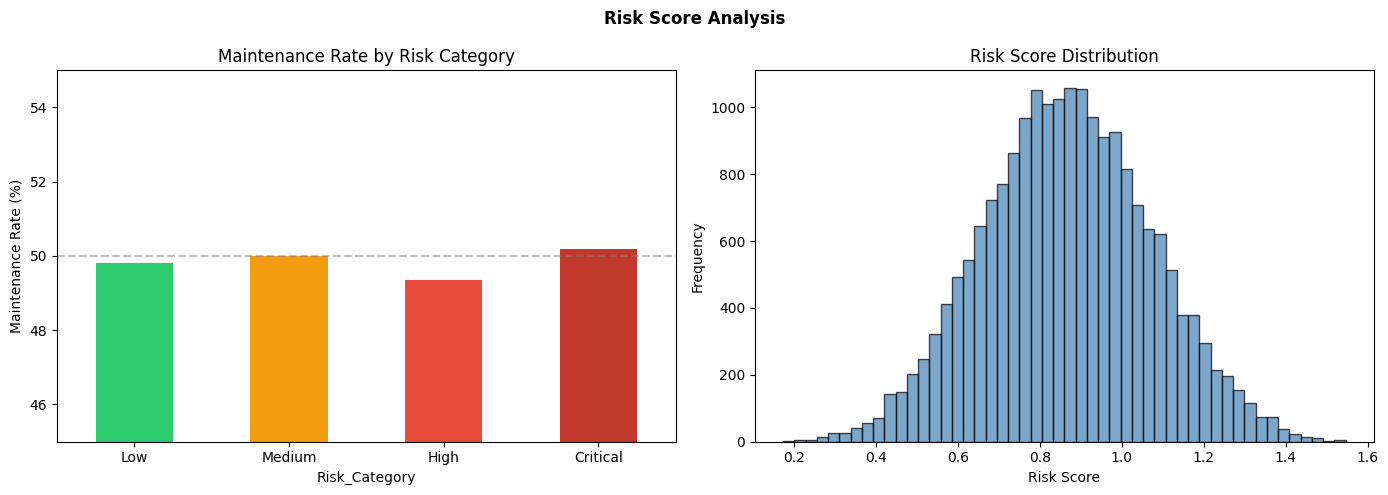

In [18]:
# 4. FEATURE ENGINEERING
df_engineered = pm_clone.copy()

# Normalize features
scaler_fe = StandardScaler()
df_engineered[features] = scaler_fe.fit_transform(df_engineered[features])

# Create composite risk score
df_engineered['Risk_Score'] = (
    abs(df_engineered['Temperature']) * 0.15 +
    abs(df_engineered['Vibration']) * 0.20 +
    abs(df_engineered['Pressure']) * 0.15 +
    abs(df_engineered['Flow_Rate']) * 0.15 +
    abs(df_engineered['RPM']) * 0.15 +
    abs(df_engineered['Operational_Hours']) * 0.20
)

# Risk categories
df_engineered['Risk_Category'] = pd.qcut(df_engineered['Risk_Score'], q=4,
                                         labels=['Low', 'Medium', 'High', 'Critical'])

print("\nRisk Score Statistics:")
print(df_engineered['Risk_Score'].describe())

print("\nMaintenance Rate by Risk Category:")
risk_analysis = df_engineered.groupby('Risk_Category')['Maintenance_Flag'].agg(['count', 'sum', 'mean'])
risk_analysis['Rate(%)'] = (risk_analysis['mean'] * 100).round(2)
print(risk_analysis[['count', 'Rate(%)']])
print("Finding: All risk categories show ~50% maintenance rate (random distribution)")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Risk Score Analysis', fontsize=12, fontweight='bold')

ax = axes[0]
risk_maint = df_engineered.groupby('Risk_Category')['Maintenance_Flag'].mean() * 100
colors = ['#2ecc71', '#f39c12', '#e74c3c', '#c0392b']
risk_maint.plot(kind='bar', ax=ax, color=colors)
ax.set_title('Maintenance Rate by Risk Category')
ax.set_ylabel('Maintenance Rate (%)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.axhline(y=50, color='gray', linestyle='--', alpha=0.5)
ax.set_ylim([45, 55])

ax = axes[1]
ax.hist(df_engineered['Risk_Score'], bins=50, color='steelblue', alpha=0.7, edgecolor='black')
ax.set_title('Risk Score Distribution')
ax.set_xlabel('Risk Score')
ax.set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('02_risk_analysis.png', dpi=300, bbox_inches='tight') # Changed save path
plt.show()

In [19]:
# 5. LIFECYCLE ANALYSIS
pm_clone['Hours_Bin'] = pd.cut(pm_clone['Operational_Hours'],
                         bins=[0, 2500, 5000, 7500, 10000],
                         labels=['Early (<2.5k)', 'Growth (2.5-5k)', 'Mature (5-7.5k)', 'Late (>7.5k)'])

lifecycle = pm_clone.groupby('Hours_Bin')['Maintenance_Flag'].agg(['count', 'sum', 'mean'])
lifecycle['Rate(%)'] = (lifecycle['mean'] * 100).round(2)

print("\nMaintenance Rate by Lifecycle Stage:")
print(lifecycle[['count', 'Rate(%)']])
print("Finding: No degradation pattern with age (49-51% range)")


Maintenance Rate by Lifecycle Stage:
                 count  Rate(%)
Hours_Bin                      
Early (<2.5k)     4950    50.55
Growth (2.5-5k)   4990    49.28
Mature (5-7.5k)   5049    49.18
Late (>7.5k)      5011    50.37
Finding: No degradation pattern with age (49-51% range)


In [20]:
# 6. DATA PREPARATION FOR ML
X = pm_clone[['Temperature', 'Vibration', 'Pressure', 'Flow_Rate', 'RPM', 'Operational_Hours']]
y = pm_clone['Maintenance_Flag']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTraining set: {len(X_train):,} samples ({len(X_train)/len(X)*100:.1f}%)")
print(f"Test set: {len(X_test):,} samples ({len(X_test)/len(X)*100:.1f}%)\nTraining maintenance rate: {y_train.mean()*100:.2f}%\nTest maintenance rate: {y_test.mean()*100:.2f}%")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Training set: 16,000 samples (80.0%)
Test set: 4,000 samples (20.0%)
Training maintenance rate: 49.84%
Test maintenance rate: 49.85%


In [21]:
# 7. MACHINE LEARNING MODELS

# Model 1: Logistic Regression
print("\n--- MODEL 1: LOGISTIC REGRESSION ---")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

y_train_pred_lr = lr_model.predict(X_train_scaled)
y_test_pred_lr = lr_model.predict(X_test_scaled)
y_test_proba_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

lr_test_acc = accuracy_score(y_test, y_test_pred_lr)
lr_test_auc = roc_auc_score(y_test, y_test_proba_lr)
lr_test_f1 = f1_score(y_test, y_test_pred_lr)

print(f"Test Accuracy: {lr_test_acc:.4f}")
print(f"Test ROC-AUC: {lr_test_auc:.4f}")
print(f"Test F1-Score: {lr_test_f1:.4f}")

# Model 2: Random Forest
print("\n--- MODEL 2: RANDOM FOREST ---")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, max_depth=15)
rf_model.fit(X_train, y_train)

y_test_pred_rf = rf_model.predict(X_test)
y_test_proba_rf = rf_model.predict_proba(X_test)[:, 1]

rf_test_acc = accuracy_score(y_test, y_test_pred_rf)
rf_test_auc = roc_auc_score(y_test, y_test_proba_rf)
rf_test_f1 = f1_score(y_test, y_test_pred_rf)

print(f"Test Accuracy: {rf_test_acc:.4f}")
print(f"Test ROC-AUC: {rf_test_auc:.4f}")
print(f"Test F1-Score: {rf_test_f1:.4f}")

# Model 3: Gradient Boosting
print("\n--- MODEL 3: GRADIENT BOOSTING ---")
gb_model = GradientBoostingClassifier(n_estimators=100, random_state=42, max_depth=5)
gb_model.fit(X_train, y_train)

y_test_pred_gb = gb_model.predict(X_test)
y_test_proba_gb = gb_model.predict_proba(X_test)[:, 1]

gb_test_acc = accuracy_score(y_test, y_test_pred_gb)
gb_test_auc = roc_auc_score(y_test, y_test_proba_gb)
gb_test_f1 = f1_score(y_test, y_test_pred_gb)

print(f"Test Accuracy: {gb_test_acc:.4f}")
print(f"Test ROC-AUC: {gb_test_auc:.4f}")
print(f"Test F1-Score: {gb_test_f1:.4f}")


--- MODEL 1: LOGISTIC REGRESSION ---
Test Accuracy: 0.4953
Test ROC-AUC: 0.5016
Test F1-Score: 0.4674

--- MODEL 2: RANDOM FOREST ---
Test Accuracy: 0.4875
Test ROC-AUC: 0.4868
Test F1-Score: 0.4631

--- MODEL 3: GRADIENT BOOSTING ---
Test Accuracy: 0.4900
Test ROC-AUC: 0.4857
Test F1-Score: 0.4676



Model Comparison Table:
              Model  Test_Accuracy  Test_ROC_AUC  Test_F1
Logistic Regression        0.49525      0.501576 0.467423
      Random Forest        0.48750      0.486814 0.463070
  Gradient Boosting        0.49000      0.485703 0.467641

Finding: All models achieve ~50% performance (baseline for balanced data)


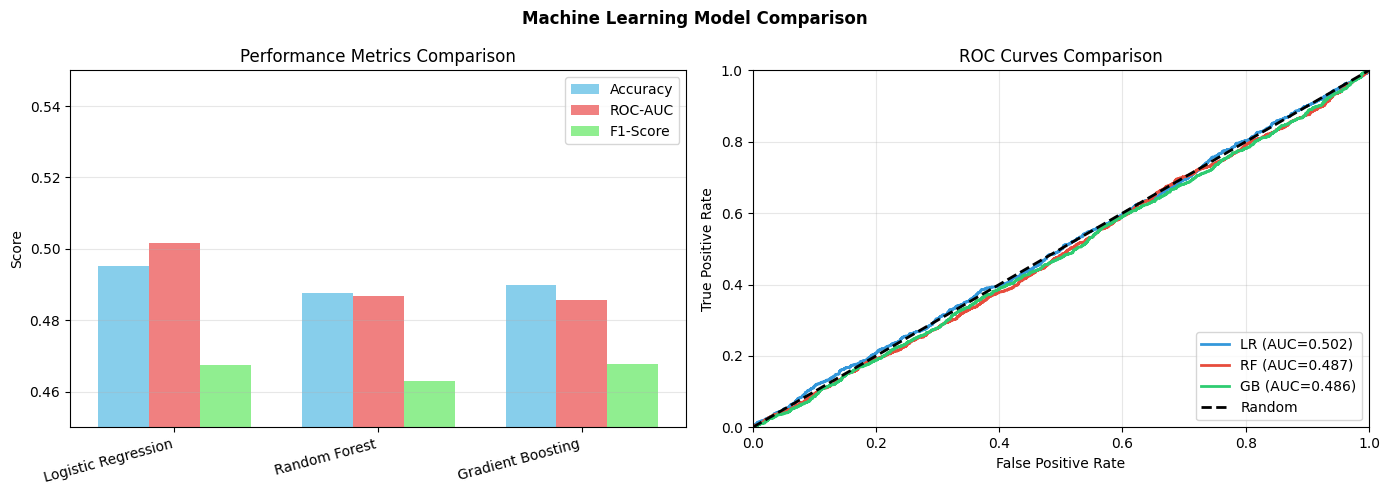

In [23]:
# 8. MODEL COMPARISON
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'Gradient Boosting'],
    'Test_Accuracy': [lr_test_acc, rf_test_acc, gb_test_acc],
    'Test_ROC_AUC': [lr_test_auc, rf_test_auc, gb_test_auc],
    'Test_F1': [lr_test_f1, rf_test_f1, gb_test_f1]
})

print("\nModel Comparison Table:")
print(comparison.to_string(index=False))
print("\nFinding: All models achieve ~50% performance (baseline for balanced data)")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Machine Learning Model Comparison', fontsize=12, fontweight='bold')

ax = axes[0]
x = np.arange(len(comparison))
width = 0.25
ax.bar(x - width, comparison['Test_Accuracy'], width, label='Accuracy', color='skyblue')
ax.bar(x, comparison['Test_ROC_AUC'], width, label='ROC-AUC', color='lightcoral')
ax.bar(x + width, comparison['Test_F1'], width, label='F1-Score', color='lightgreen')
ax.set_ylabel('Score')
ax.set_title('Performance Metrics Comparison')
ax.set_xticks(x)
ax.set_xticklabels(comparison['Model'], rotation=15, ha='right')
ax.legend()
ax.set_ylim([0.45, 0.55])
ax.grid(axis='y', alpha=0.3)

ax = axes[1]
colors_roc = ['#3498db', '#e74c3c', '#2ecc71']
for idx, (name, proba) in enumerate([('LR', y_test_proba_lr), ('RF', y_test_proba_rf), ('GB', y_test_proba_gb)]):
    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, lw=2, label=f'{name} (AUC={roc_auc:.3f})', color=colors_roc[idx])

ax.plot([0, 1], [0, 1], 'k--', lw=2, label='Random')
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves Comparison')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
# 9. FEATURE IMPORTANCE
# Logistic Regression
lr_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr_model.coef_[0]
}).sort_values('Coefficient', key=abs, ascending=False)

print("\nLogistic Regression Coefficients:")
print(lr_importance.to_string(index=False))

# Random Forest
rf_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nRandom Forest Feature Importance:")
print(rf_importance.to_string(index=False))

# Gradient Boosting
gb_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': gb_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nGradient Boosting Feature Importance:")
print(gb_importance.to_string(index=False))


Logistic Regression Coefficients:
          Feature  Coefficient
      Temperature    -0.027902
              RPM    -0.026921
Operational_Hours    -0.013920
        Flow_Rate     0.013734
         Pressure    -0.013390
        Vibration     0.009173

Random Forest Feature Importance:
          Feature  Importance
              RPM    0.170854
        Flow_Rate    0.167062
         Pressure    0.165829
Operational_Hours    0.165751
      Temperature    0.165290
        Vibration    0.165214

Gradient Boosting Feature Importance:
          Feature  Importance
Operational_Hours    0.172327
        Vibration    0.170721
        Flow_Rate    0.168723
              RPM    0.165434
         Pressure    0.162276
      Temperature    0.160520


In [25]:
# 10. CROSS-VALIDATION

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_cv = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, max_depth=15),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42, max_depth=5)
}

cv_results = {}

for model_name, model in models_cv.items():
    if model_name == 'Logistic Regression':
        scores = cross_val_score(model, X_train_scaled, y_train, cv=cv, scoring='roc_auc')
    else:
        scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')

    cv_results[model_name] = scores
    print(f"\n{model_name}:")
    print(f"  CV Scores: {scores}")
    print(f"  Mean ROC-AUC: {scores.mean():.4f} (±{scores.std():.4f})")


Logistic Regression:
  CV Scores: [0.5124136  0.50203186 0.51526714 0.51233782 0.50256957]
  Mean ROC-AUC: 0.5089 (±0.0055)

Random Forest:
  CV Scores: [0.52214768 0.49901776 0.48439028 0.4929845  0.50280902]
  Mean ROC-AUC: 0.5003 (±0.0126)

Gradient Boosting:
  CV Scores: [0.50209768 0.50655417 0.50441059 0.5097999  0.50234691]
  Mean ROC-AUC: 0.5050 (±0.0029)
